# 01 – Synthetic data

Deterministic SEIRDDobs trajectories for two R0 scenarios (age-structured, 16 age classes, weekly time grid) and the weekly incidence derived from them, true and with Negative Binomial noise.

Two modes, set by `REGENERATE` below:

- `False` (default): load the files already in `data/synthetic/`.
- `True`: generate everything again (same seed, same data) and save it in `DATA_DIR`.

Then the data are plotted: aggregated, and by age class.

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt

from pinnvsmech.constants import ifr_hetero, N_age, xi, epsilon
from pinnvsmech.data.load_matrices import load_contact_matrix
from pinnvsmech.data.synthetic import (
    generate_deterministic_data, save_deterministic_data,
    compute_incidences, save_scenarios, load_scenarios,
    plot_noise_comparison_agg_grid, plot_age_trajectories,
)
from pinnvsmech.paths import SYNTHETIC_DIR, OUTPUTS_DIR

In [ ]:
# ---- Settings -------------------------------------------------------------
REGENERATE = False                    # True: generate the data again; False: load them
DATA_DIR = SYNTHETIC_DIR               # where to read/write. Use OUTPUTS_DIR / "synthetic" to avoid overwriting data/synthetic
SAVE_FIGS = False                      # save the figures in FIG_DIR
FIG_DIR = OUTPUTS_DIR / "figures" / "synthetic_data"

# Only used if REGENERATE = True
P_TRAIN = np.array([[1.5, 15.], [2., 15.]])   # columns: R0, delta (delta is not used for the incidence)
COUNTRY = "United Kingdom of Great Britain"   # contact matrix (Prem et al.)
INF_T0 = 1000                                 # total initial infections
DOMAIN = (0, 245)                             # days (35 weeks)
NOISE_LEVELS = {"light": 100, "mild": 50}     # Negative Binomial dispersion r (smaller = noisier)
SEED = 42

## 1. Generate (optional)

In [9]:
if REGENERATE:
    C = load_contact_matrix(COUNTRY)
    x_train, y_train, idx_train = generate_deterministic_data(
        P_TRAIN, C, N_age, ifr_hetero, epsilon, xi, inf_t0=INF_T0, domain=DOMAIN, step=7)
    print("x_train:", x_train.shape, "y_train:", y_train.shape, "idx_train:", idx_train.shape)

    save_deterministic_data(x_train, y_train, idx_train, P_TRAIN, folder=DATA_DIR)

    scenarios = compute_incidences(x_train, y_train, idx_train, N_age, noise_levels=NOISE_LEVELS, seed=SEED)
    save_scenarios(scenarios, out_dir=DATA_DIR)
else:
    print("Skipped: loading existing data from", DATA_DIR)

/home/mrama/venvs/pinns/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Generating training data:   0%|          | 0/2 [00:00<?, ?it/s]

x_train: (72, 3) y_train: (72, 96) idx_train: (72, 1)
Saved /home/mrama/SINNs/PINNs_epi/Repo_GitHub/PINNvsMechanistic-models-for-epidemic-modeling-and-forecasting/data/synthetic/synthetic_R0_1.5_noise_light.pkl
Saved /home/mrama/SINNs/PINNs_epi/Repo_GitHub/PINNvsMechanistic-models-for-epidemic-modeling-and-forecasting/data/synthetic/synthetic_R0_1.5_noise_mild.pkl
Saved /home/mrama/SINNs/PINNs_epi/Repo_GitHub/PINNvsMechanistic-models-for-epidemic-modeling-and-forecasting/data/synthetic/synthetic_R0_2.0_noise_light.pkl
Saved /home/mrama/SINNs/PINNs_epi/Repo_GitHub/PINNvsMechanistic-models-for-epidemic-modeling-and-forecasting/data/synthetic/synthetic_R0_2.0_noise_mild.pkl


## 2. Load

In [10]:
scenarios = load_scenarios(DATA_DIR)

for R0_val, sc in scenarios.items():
    print(f"R0 = {R0_val}: {len(sc['t'])} weekly points, noise levels: {list(sc['noisy'])}, "
          f"age incidence {sc['age incidence'].shape}")

R0 = 1.5: 35 weekly points, noise levels: ['light', 'mild'], age incidence (35, 16)
R0 = 2.0: 35 weekly points, noise levels: ['light', 'mild'], age incidence (35, 16)


## 3. Weekly incidence, aggregated

True incidence (black) and noisy incidence (red); one row per noise level, one column per R0.

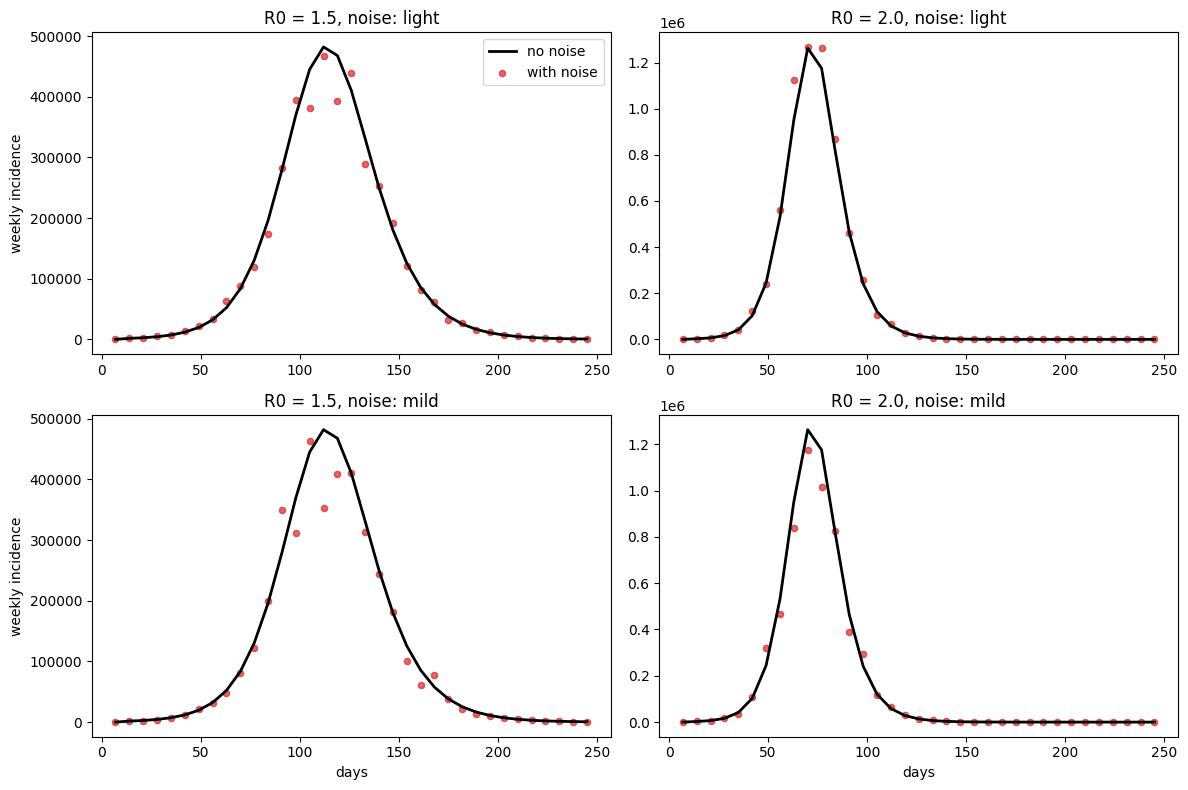

In [12]:
fig_agg = plot_noise_comparison_agg_grid(scenarios)
if SAVE_FIGS:
    os.makedirs(FIG_DIR, exist_ok=True)
    fig_agg.savefig(FIG_DIR / "ages_incidences_aggregated.jpg", dpi=300)
plt.show()

## 4. Weekly incidence by age class

True incidence (no noise); one panel per R0, one line per age class.

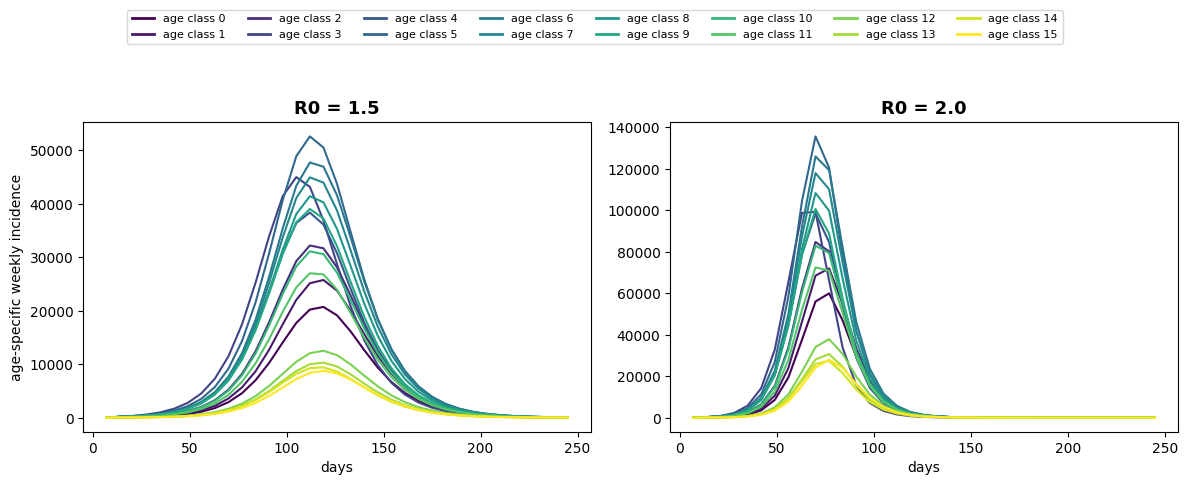

In [13]:
fig_age = plot_age_trajectories(list(scenarios), data_dir=DATA_DIR)
if SAVE_FIGS:
    os.makedirs(FIG_DIR, exist_ok=True)
    #fig_age.savefig(FIG_DIR / "ages_incidences_all_nonoise.jpg", dpi=300, bbox_inches="tight")
plt.show()